# Waveform and Acoustic Analysis of Normal vs Dysarthric Speech

This notebook presents a comparative acoustic analysis of **normal** and **dysarthric** male speech from the [TORGO dataset](http://www.cs.toronto.edu/~complingweb/data/TORGO/torgo.html). We examine several acoustic features to highlight the key differences between the two speech types:

## 0. Imports & Setup

In [11]:
import os
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 12,
    'axes.labelsize': 10,
    'font.family': 'sans-serif',
})

NORMAL_COLOR = '#2196F3' 
DYS_COLOR    = '#F44336'

## 1. Load Audio Files

In [12]:
base_path  = os.path.join('Dataset', 'torgo_data')
normal_dir = os.path.join(base_path, 'non_dysarthria_male')
dys_dir    = os.path.join(base_path, 'dysarthria_male')

# same sentence spoken in first two
normal_file = 'MC04_Session1_0149.wav'
dys_file    = 'M01_Session2_3_0069.wav'
# dys_file    = 'M01_Session1_0005.wav'
# dys_file    = 'M01_Session2_3_0224.wav'
# dys_file    = 'M01_Session2_3_0232.wav'
# dys_file    = 'M02_Session2_0131.wav'
# dys_file    = 'M02_Session2_0213.wav'
# dys_file    = 'M04_Session2_0167.wav'

normal_audio, sr_n = librosa.load(os.path.join(normal_dir, normal_file), sr=None)
dys_audio,    sr_d = librosa.load(os.path.join(dys_dir,    dys_file),    sr=None)

print(f"Normal     : {normal_file}   (sr={sr_n} Hz, {len(normal_audio)/sr_n:.2f}s)")
print(f"Dysarthric : {dys_file}   (sr={sr_d} Hz, {len(dys_audio)/sr_d:.2f}s)")

Normal     : MC04_Session1_0149.wav   (sr=16000 Hz, 3.42s)
Dysarthric : M01_Session2_3_0069.wav   (sr=16000 Hz, 6.85s)


## 2. Waveform Comparison

The raw time-domain waveform gives a first look at **amplitude envelope** and **energy distribution**. Dysarthric speech often shows reduced dynamic range, irregular bursts, or longer pauses.

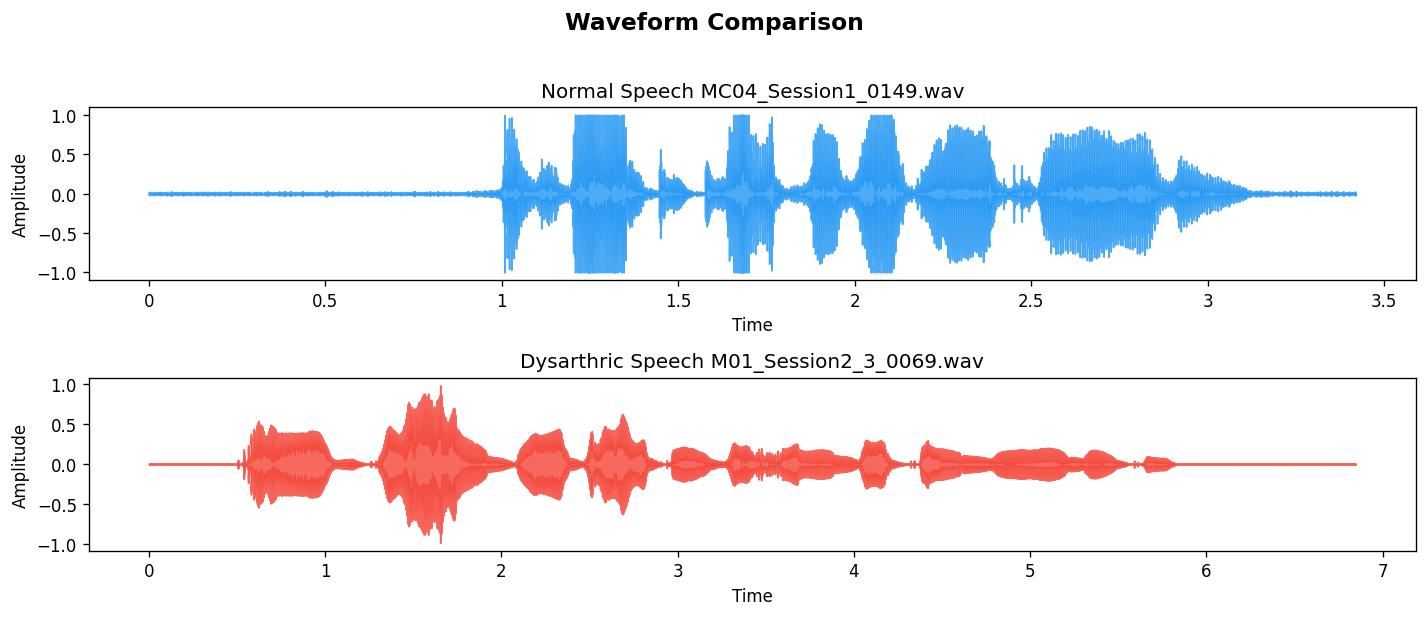

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=False)

librosa.display.waveshow(normal_audio, sr=sr_n, ax=axes[0], color=NORMAL_COLOR, alpha=0.8)
axes[0].set_title(f'Normal Speech {normal_file}')
axes[0].set_ylabel('Amplitude')

librosa.display.waveshow(dys_audio, sr=sr_d, ax=axes[1], color=DYS_COLOR, alpha=0.8)
axes[1].set_title(f'Dysarthric Speech {dys_file}')
axes[1].set_ylabel('Amplitude')

plt.suptitle('Waveform Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 3a. STFT Spectrogram

The Short-Time Fourier Transform (STFT) spectrogram shows frequency content over time. Normal speech has clear, well-defined formant bands; dysarthric speech often has smeared or irregular harmonic structure.

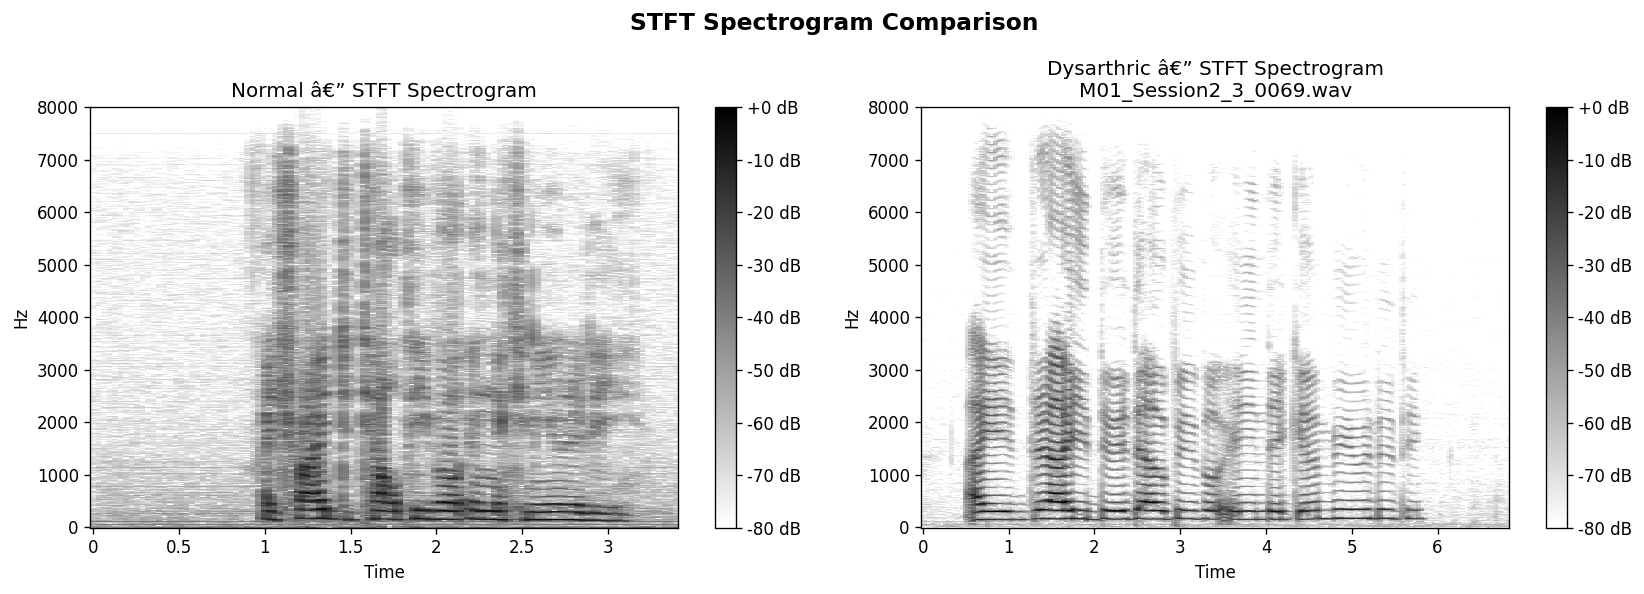

In [100]:
n_fft      = 2048
hop_length = 512

D_normal = librosa.amplitude_to_db(np.abs(librosa.stft(normal_audio, n_fft=n_fft, hop_length=hop_length)), ref=np.max)
D_dys    = librosa.amplitude_to_db(np.abs(librosa.stft(dys_audio,    n_fft=n_fft, hop_length=hop_length)), ref=np.max)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

img1 = librosa.display.specshow(D_normal, sr=sr_n, hop_length=hop_length, x_axis='time', y_axis='hz', ax=axes[0], cmap='gray_r')
axes[0].set_title('Normal â€” STFT Spectrogram')
fig.colorbar(img1, ax=axes[0], format='%+2.0f dB')

img2 = librosa.display.specshow(D_dys, sr=sr_d, hop_length=hop_length, x_axis='time', y_axis='hz', ax=axes[1], cmap='gray_r')
axes[1].set_title(f'Dysarthric â€” STFT Spectrogram\n{dys_file}')
fig.colorbar(img2, ax=axes[1], format='%+2.0f dB')

plt.suptitle('STFT Spectrogram Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3b. Mel Spectrogram

The Mel spectrogram maps frequency to the Mel scale (*perceptually uniform*), emphasising speech-relevant bands. It is the most common input feature for speech pathology detection models.

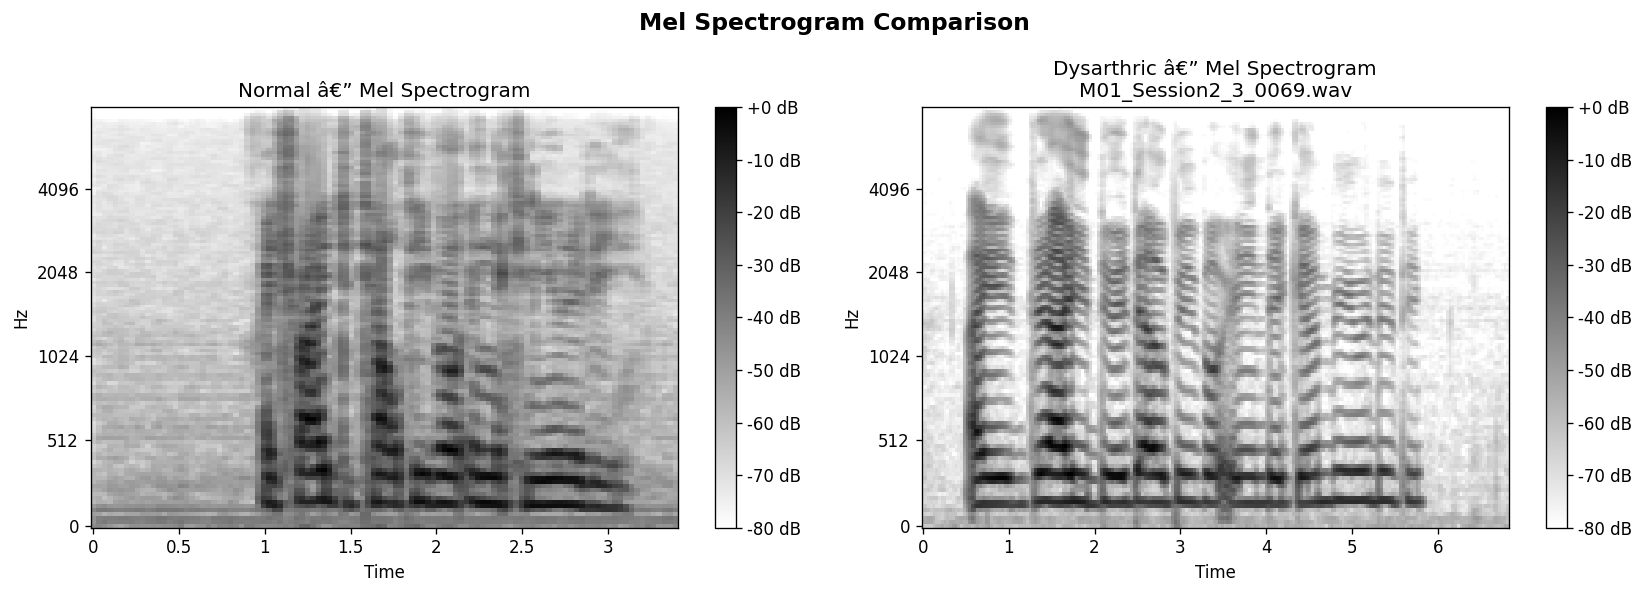

In [101]:
n_mels = 128

mel_normal = librosa.feature.melspectrogram(y=normal_audio, sr=sr_n, n_mels=n_mels, hop_length=hop_length)
mel_dys    = librosa.feature.melspectrogram(y=dys_audio,    sr=sr_d, n_mels=n_mels, hop_length=hop_length)

mel_db_normal = librosa.power_to_db(mel_normal, ref=np.max)
mel_db_dys    = librosa.power_to_db(mel_dys,    ref=np.max)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

img1 = librosa.display.specshow(mel_db_normal, sr=sr_n, hop_length=hop_length, x_axis='time', y_axis='mel', ax=axes[0], cmap='gray_r')
axes[0].set_title('Normal â€” Mel Spectrogram')
fig.colorbar(img1, ax=axes[0], format='%+2.0f dB')

img2 = librosa.display.specshow(mel_db_dys, sr=sr_d, hop_length=hop_length, x_axis='time', y_axis='mel', ax=axes[1], cmap='gray_r')
axes[1].set_title(f'Dysarthric â€” Mel Spectrogram\n{dys_file}')
fig.colorbar(img2, ax=axes[1], format='%+2.0f dB')

plt.suptitle('Mel Spectrogram Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. MFCCs (Mel-Frequency Cepstral Coefficients)

MFCCs compactly represent the **spectral envelope** of speech. The first ~13 coefficients capture most of the phonetic information. Dysarthric speech typically shows more variance and less distinct MFCC trajectories.

In [ ]:
MFCC_N_FFT     = 400
MFCC_HOP       = 80
n_mfcc         = 13

mfcc_normal = librosa.feature.mfcc(y=normal_audio, sr=sr_n, n_mfcc=n_mfcc,
                                    n_fft=MFCC_N_FFT, hop_length=MFCC_HOP)
mfcc_dys    = librosa.feature.mfcc(y=dys_audio,    sr=sr_d, n_mfcc=n_mfcc,
                                    n_fft=MFCC_N_FFT, hop_length=MFCC_HOP)

delta_normal  = librosa.feature.delta(mfcc_normal)
delta_dys     = librosa.feature.delta(mfcc_dys)
delta2_normal = librosa.feature.delta(mfcc_normal, order=2)
delta2_dys    = librosa.feature.delta(mfcc_dys,    order=2)

for data_n, data_d, title in [
    (mfcc_normal,   mfcc_dys,    'MFCCs'),
    (delta_normal,  delta_dys,   'Delta MFCCs (Velocity)'),
    (delta2_normal, delta2_dys,  'Delta-Delta MFCCs (Acceleration)'),
]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    img1 = librosa.display.specshow(data_n, sr=sr_n, hop_length=MFCC_HOP, x_axis='time', ax=axes[0], cmap='coolwarm')
    axes[0].set_title(f'Normal — {title}')
    axes[0].set_ylabel('Coefficient')
    fig.colorbar(img1, ax=axes[0])
    img2 = librosa.display.specshow(data_d, sr=sr_d, hop_length=MFCC_HOP, x_axis='time', ax=axes[1], cmap='coolwarm')
    axes[1].set_title(f'Dysarthric — {title}')
    axes[1].set_ylabel('Coefficient')
    fig.colorbar(img2, ax=axes[1])
    plt.suptitle(f'{title} Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, data_n, data_d, title in zip(
    axes,
    [mfcc_normal,   delta_normal,  delta2_normal],
    [mfcc_dys,      delta_dys,     delta2_dys],
    ['MFCC',        'Delta',       'Delta-Delta'],
):
    ax.bar(np.arange(n_mfcc) - 0.2, data_n.mean(axis=1), width=0.4, label='Normal',     color=NORMAL_COLOR, alpha=0.8)
    ax.bar(np.arange(n_mfcc) + 0.2, data_d.mean(axis=1), width=0.4, label='Dysarthric', color=DYS_COLOR,    alpha=0.8)
    ax.set_xticks(np.arange(n_mfcc))
    ax.set_xticklabels([f'C{i+1}' for i in range(n_mfcc)], fontsize=8)
    ax.set_xlabel('Coefficient')
    ax.set_ylabel('Mean Value')
    ax.set_title(f'Mean {title} Coefficients')
    ax.legend(fontsize=8)
plt.suptitle('Mean MFCC / Delta / Delta-Delta — Normal vs Dysarthric', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, data_n, data_d, title in zip(
    axes,
    [mfcc_normal,   delta_normal,  delta2_normal],
    [mfcc_dys,      delta_dys,     delta2_dys],
    ['MFCC',        'Delta',       'Delta-Delta'],
):
    ax.plot(np.arange(n_mfcc), data_n.mean(axis=1), color=NORMAL_COLOR, linewidth=2,
            marker='o', markersize=4, label=f'Normal — {normal_file}')
    ax.plot(np.arange(n_mfcc), data_d.mean(axis=1), color=DYS_COLOR,    linewidth=2,
            marker='o', markersize=4, label=f'Dysarthric — {dys_file}')
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.set_xticks(np.arange(n_mfcc))
    ax.set_xlabel('MFCC Coefficients')
    ax.set_ylabel('Average Amplitude')
    ax.set_title(f'{title} of Audio Files')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Pitch (F0) Contour

Fundamental frequency (F0) tracks **vocal fold vibration rate**. Normal speech shows smooth, well-controlled pitch contours. Dysarthric speech often has **irregular pitch**, reduced pitch range, or breaks in voicing.

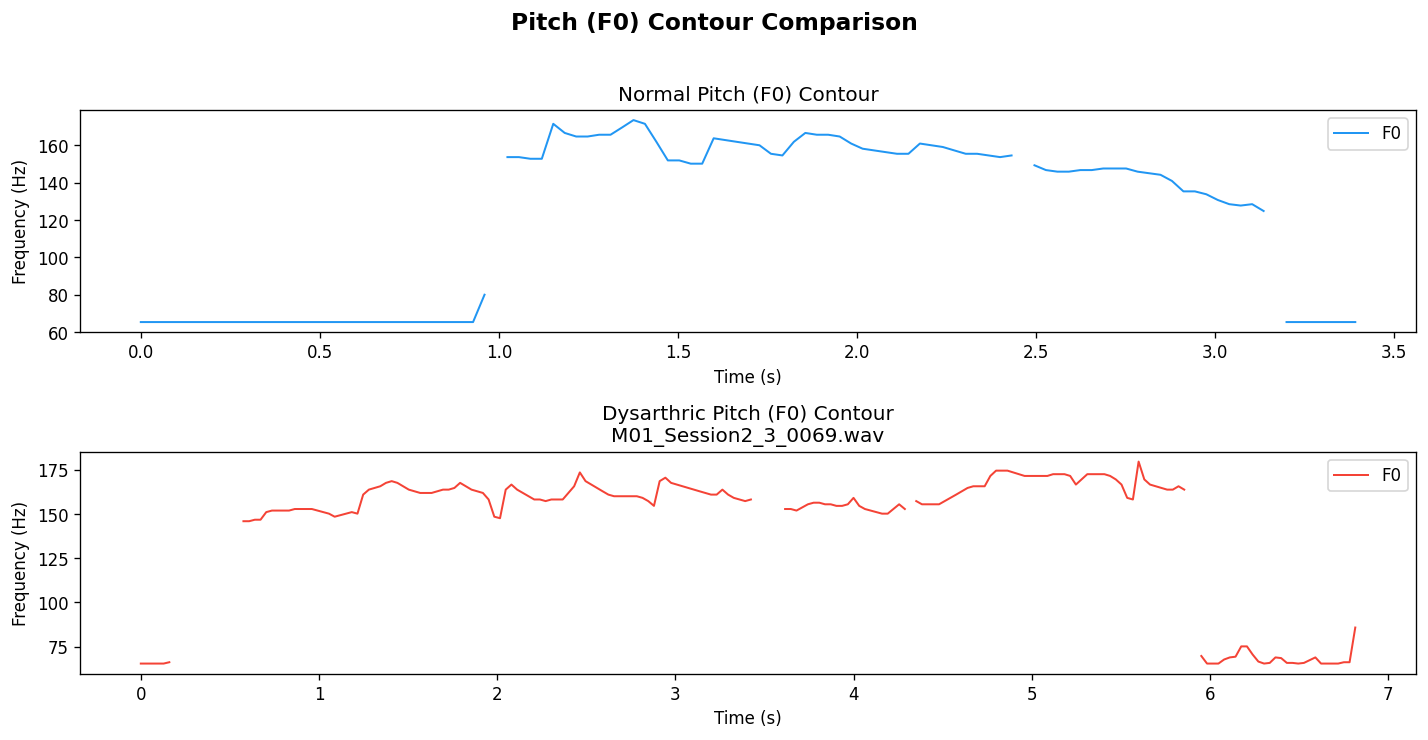

Normal     F0 â€” mean: 121.6 Hz  std: 43.3 Hz  voiced%: 97.2%
Dysarthric F0 â€” mean: 144.7 Hz  std: 36.2 Hz  voiced%: 90.7%


In [ ]:
f0_normal, voiced_flag_n, _ = librosa.pyin(normal_audio, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C7'), sr=sr_n)
f0_dys,    voiced_flag_d, _ = librosa.pyin(dys_audio,    fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C7'), sr=sr_d)

times_f0_n = librosa.times_like(f0_normal, sr=sr_n)
times_f0_d = librosa.times_like(f0_dys,    sr=sr_d)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(times_f0_n, f0_normal, color=NORMAL_COLOR, linewidth=1.2, label='F0')
axes[0].set_title('Normal Pitch (F0) Contour')
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_xlabel('Time (s)')
axes[0].legend()

axes[1].plot(times_f0_d, f0_dys, color=DYS_COLOR, linewidth=1.2, label='F0')
axes[1].set_title(f'Dysarthric Pitch (F0) Contour\n{dys_file}')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_xlabel('Time (s)')
axes[1].legend()

plt.suptitle('Pitch (F0) Contour Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# voiced frame stats
f0_n_voiced = f0_normal[~np.isnan(f0_normal)]
f0_d_voiced = f0_dys[~np.isnan(f0_dys)]
print(f"Normal     F0” mean: {f0_n_voiced.mean():.1f} Hz  std: {f0_n_voiced.std():.1f} Hz  voiced%: {100*len(f0_n_voiced)/len(f0_normal):.1f}%")
print(f"Dysarthric F0” mean: {f0_d_voiced.mean():.1f} Hz  std: {f0_d_voiced.std():.1f} Hz  voiced%: {100*len(f0_d_voiced)/len(f0_dys):.1f}%")

### Metadata Summary

#### Audio File Basics

| Item | Normal Speech | Dysarthric Speech |
|---|---:|---:|
| File name | `MC04_Session1_0149.wav` | `M01_Session2_3_0069.wav` |
| Sampling rate | 16000 Hz | 16000 Hz |

#### Analysis Parameters Used in This Notebook

| Parameter | Value |
|---|---:|
| `hop_length` | 512 samples |
| `n_fft` (STFT) | 2048 |
| `n_mels` (Mel Spectrogram) | 128 |
| `n_mfcc` (MFCC) | 13 |
| Pitch extraction method | `librosa.pyin` |
| Pitch search range | C2 to C7 |

Derived Values
- Frame duration = 2048 / 16000 = **128 ms**
- Hop duration = 512 / 16000 = **32 ms**
- STFT frequency resolution = 16000 / 2048 = **7.8125 Hz/bin**

> Note: Audio is loaded with `librosa.load(..., sr=None)`, so native sample rate is preserved. By default, librosa loads audio as mono.

# Training a Classifier on Acoustic Features

## 6.1  Imports

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
import librosa
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report)


## 6.2  Build Dataset — Two Feature Vectors

We extract two variants in a single pass for direct comparison:

| Name | Components | Dim |
|---|---|---:|
| **39-dim** | mean(MFCC) + mean(delta) + mean(delta-delta) | 39 |
| **78-dim** | + std of each of the above | 78 |

The 39-dim version is the standard baseline in the literature.
The 78-dim version adds std, which captures *how much each coefficient moves* --
dysarthric speakers with restricted articulation show lower std on higher coefficients.


In [ ]:
DATA_ROOT = os.path.join("Dataset", "torgo_data")
FOLDERS = {
    "dysarthria_male":       1,
    "dysarthria_female":     1,
    "non_dysarthria_male":   0,
    "non_dysarthria_female": 0,
}
N_MFCC     = 13
HOP_LENGTH = 512
SR         = 16000
MIN_FRAMES = 3

feats_39, feats_78, labels, speaker_ids = [], [], [], []

for folder, label in FOLDERS.items():
    folder_path = os.path.join(DATA_ROOT, folder)
    wav_files   = [f for f in os.listdir(folder_path) if f.endswith(".wav")]
    for fname in wav_files:
        fpath = os.path.join(folder_path, fname)
        try:
            y, _ = librosa.load(fpath, sr=SR, mono=True)
            mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, hop_length=HOP_LENGTH)
            if mfcc.shape[1] < MIN_FRAMES:
                continue
            w = min(9, mfcc.shape[1])
            if w % 2 == 0: w -= 1
            delta  = librosa.feature.delta(mfcc, width=w)
            delta2 = librosa.feature.delta(mfcc, order=2, width=w)

            vec_39 = np.concatenate([
                np.mean(mfcc,   axis=1),
                np.mean(delta,  axis=1),
                np.mean(delta2, axis=1),
            ])
            vec_78 = np.concatenate([
                np.mean(mfcc,   axis=1), np.std(mfcc,   axis=1),
                np.mean(delta,  axis=1), np.std(delta,  axis=1),
                np.mean(delta2, axis=1), np.std(delta2, axis=1),
            ])
            feats_39.append(vec_39)
            feats_78.append(vec_78)
            labels.append(label)
            speaker_ids.append(fname.split("_")[0])  # e.g. M01, FC01
        except Exception as e:
            print(f"Skipped {fname}: {e}")

X39         = np.array(feats_39)
X78         = np.array(feats_78)
y_all       = np.array(labels)
speaker_arr = np.array(speaker_ids)
print(f"Samples: {X39.shape[0]}  |  39-dim: {X39.shape}  |  78-dim: {X78.shape}")
print(f"Dysarthric: {y_all.sum()}  |  Normal: {(y_all == 0).sum()}")

C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=686
  warnings.warn(
C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=421
  warnings.warn(
C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=151
  warnings.warn(
C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=134
  warnings.warn(
C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=423
  warnings.warn(
C:\Users\varun\AppData\Roaming\Python\Python312\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048

Skipped F01_Session1_0068.wav: 
Samples: 1991  |  39-dim: (1991, 39)  |  78-dim: (1991, 78)
Dysarthric: 991  |  Normal: 1000


In [ ]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

col_names_39 = (
    [f"mfcc_mean_{i}"   for i in range(1, 14)] +
    [f"delta_mean_{i}"  for i in range(1, 14)] +
    [f"delta2_mean_{i}" for i in range(1, 14)]
)
col_names_78 = (
    [f"mfcc_mean_{i}"   for i in range(1, 14)] +
    [f"mfcc_std_{i}"    for i in range(1, 14)] +
    [f"delta_mean_{i}"  for i in range(1, 14)] +
    [f"delta_std_{i}"   for i in range(1, 14)] +
    [f"delta2_mean_{i}" for i in range(1, 14)] +
    [f"delta2_std_{i}"  for i in range(1, 14)]
)

df39 = pd.DataFrame(X39, columns=col_names_39)
df39["label"] = ["dysarthric" if l == 1 else "normal" for l in y_all]

df78 = pd.DataFrame(X78, columns=col_names_78)
df78["label"] = df39["label"]

print("39-dim features (first 5 rows):")
display(df39.head())

print("\n78-dim features (first 5 rows):")
display(df78.head())

39-dim features (first 5 rows):


,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,mfcc_mean_8,mfcc_mean_9,mfcc_mean_10,mfcc_mean_11,mfcc_mean_12,mfcc_mean_13,delta_mean_1,delta_mean_2,delta_mean_3,delta_mean_4,delta_mean_5,delta_mean_6,delta_mean_7,delta_mean_8,delta_mean_9,delta_mean_10,delta_mean_11,delta_mean_12,delta_mean_13,delta2_mean_1,delta2_mean_2,delta2_mean_3,delta2_mean_4,delta2_mean_5,delta2_mean_6,delta2_mean_7,delta2_mean_8,delta2_mean_9,delta2_mean_10,delta2_mean_11,delta2_mean_12,delta2_mean_13,label
0,-148.75,92.92,-2.38,30.84,9.24,5.83,-0.12,5.09,-8.00,1.26,-7.36,2.34,-6.69,0.02,-0.01,0.00,0.01,-0.00,-0.00,-0.01,-0.01,-0.00,-0.01,-0.02,-0.01,-0.01,-0.03,0.00,0.02,0.01,0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.01,0.00,dysarthric
1,-133.42,92.83,-5.07,27.97,5.47,7.24,1.01,5.60,-12.05,-0.67,-6.77,1.84,-5.60,0.04,-0.01,-0.01,0.01,-0.01,0.00,0.01,-0.01,-0.01,-0.01,0.00,0.02,-0.00,-0.03,0.02,0.01,-0.01,0.00,0.00,0.00,0.00,0.01,0.01,-0.01,0.00,0.01,dysarthric
2,-164.96,82.09,0.02,29.99,9.38,11.03,0.46,11.02,-5.70,5.18,-2.50,1.86,-7.56,0.02,-0.00,-0.01,-0.01,-0.00,-0.01,-0.01,-0.01,0.01,0.02,0.01,0.01,0.01,-0.05,0.02,0.01,-0.02,-0.00,0.00,0.00,0.01,0.01,-0.00,0.00,-0.01,0.00,dysarthric
3,-158.73,84.35,3.73,31.41,11.56,9.30,-2.19,9.51,-9.57,4.47,-5.80,-0.47,-7.79,0.02,-0.00,0.03,0.02,0.02,0.03,0.01,-0.01,0.00,-0.00,-0.01,0.00,0.00,-0.03,0.01,-0.00,-0.00,0.01,0.00,0.01,0.01,0.00,-0.01,0.00,0.00,-0.00,dysarthric
4,-170.84,87.46,-5.35,25.67,7.38,7.97,2.14,9.16,-6.20,5.92,-4.27,1.48,-0.84,-0.13,0.01,0.02,0.01,0.00,0.04,0.07,-0.00,0.04,0.01,-0.00,0.01,0.01,-0.13,0.03,0.02,-0.02,-0.02,-0.02,-0.02,-0.01,0.03,-0.01,-0.00,0.01,0.01,dysarthric



78-dim features (first 5 rows):


,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,mfcc_mean_8,mfcc_mean_9,mfcc_mean_10,mfcc_mean_11,mfcc_mean_12,mfcc_mean_13,mfcc_std_1,mfcc_std_2,mfcc_std_3,mfcc_std_4,mfcc_std_5,mfcc_std_6,mfcc_std_7,mfcc_std_8,mfcc_std_9,mfcc_std_10,mfcc_std_11,mfcc_std_12,mfcc_std_13,delta_mean_1,delta_mean_2,delta_mean_3,delta_mean_4,delta_mean_5,delta_mean_6,delta_mean_7,delta_mean_8,delta_mean_9,delta_mean_10,delta_mean_11,delta_mean_12,delta_mean_13,delta_std_1,delta_std_2,delta_std_3,delta_std_4,delta_std_5,delta_std_6,delta_std_7,delta_std_8,delta_std_9,delta_std_10,delta_std_11,delta_std_12,delta_std_13,delta2_mean_1,delta2_mean_2,delta2_mean_3,delta2_mean_4,delta2_mean_5,delta2_mean_6,delta2_mean_7,delta2_mean_8,delta2_mean_9,delta2_mean_10,delta2_mean_11,delta2_mean_12,delta2_mean_13,delta2_std_1,delta2_std_2,delta2_std_3,delta2_std_4,delta2_std_5,delta2_std_6,delta2_std_7,delta2_std_8,delta2_std_9,delta2_std_10,delta2_std_11,delta2_std_12,delta2_std_13,label
0,-148.75,92.92,-2.38,30.84,9.24,5.83,-0.12,5.09,-8.00,1.26,-7.36,2.34,-6.69,105.24,33.17,25.11,17.65,15.16,9.95,12.85,14.21,11.67,11.02,13.02,7.08,8.14,0.02,-0.01,0.00,0.01,-0.00,-0.00,-0.01,-0.01,-0.00,-0.01,-0.02,-0.01,-0.01,17.48,6.33,4.76,2.82,2.88,1.92,2.18,2.36,1.81,1.83,2.09,1.24,1.41,-0.03,0.00,0.02,0.01,0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.01,0.00,9.06,3.90,2.87,1.74,1.65,1.26,1.38,1.25,1.14,1.15,1.33,0.77,0.94,dysarthric
1,-133.42,92.83,-5.07,27.97,5.47,7.24,1.01,5.60,-12.05,-0.67,-6.77,1.84,-5.60,129.19,30.47,24.35,13.18,14.28,8.98,11.87,13.67,15.78,13.16,12.57,7.17,8.56,0.04,-0.01,-0.01,0.01,-0.01,0.00,0.01,-0.01,-0.01,-0.01,0.00,0.02,-0.00,17.30,5.37,3.97,2.04,2.56,1.67,1.64,1.95,2.13,2.01,2.06,1.25,1.27,-0.03,0.02,0.01,-0.01,0.00,0.00,0.00,0.00,0.01,0.01,-0.01,0.00,0.01,9.29,3.67,2.29,1.09,1.39,0.98,1.11,1.23,1.22,1.13,1.30,0.88,0.79,dysarthric
2,-164.96,82.09,0.02,29.99,9.38,11.03,0.46,11.02,-5.70,5.18,-2.50,1.86,-7.56,115.02,23.63,25.61,14.59,14.29,7.88,13.62,12.72,11.06,9.44,10.47,7.80,8.00,0.02,-0.00,-0.01,-0.01,-0.00,-0.01,-0.01,-0.01,0.01,0.02,0.01,0.01,0.01,17.31,5.07,4.26,2.79,2.75,1.47,2.29,2.07,1.64,1.54,1.81,1.47,1.29,-0.05,0.02,0.01,-0.02,-0.00,0.00,0.00,0.01,0.01,-0.00,0.00,-0.01,0.00,7.28,3.07,2.24,1.48,1.63,0.78,1.30,1.32,0.92,0.96,1.03,0.90,0.91,dysarthric
3,-158.73,84.35,3.73,31.41,11.56,9.30,-2.19,9.51,-9.57,4.47,-5.80,-0.47,-7.79,108.51,35.29,21.22,17.15,17.07,9.92,14.84,11.15,13.39,9.86,12.74,10.16,9.41,0.02,-0.00,0.03,0.02,0.02,0.03,0.01,-0.01,0.00,-0.00,-0.01,0.00,0.00,13.00,6.87,3.62,2.33,3.17,1.78,1.90,1.72,2.00,1.51,2.00,1.54,1.82,-0.03,0.01,-0.00,-0.00,0.01,0.00,0.01,0.01,0.00,-0.01,0.00,0.00,-0.00,4.62,3.83,1.82,1.08,1.74,0.93,1.01,1.04,1.08,0.90,0.99,0.83,1.03,dysarthric
4,-170.84,87.46,-5.35,25.67,7.38,7.97,2.14,9.16,-6.20,5.92,-4.27,1.48,-0.84,113.11,29.80,27.40,19.85,17.63,11.61,14.27,11.61,10.46,8.43,12.40,10.08,6.36,-0.13,0.01,0.02,0.01,0.00,0.04,0.07,-0.00,0.04,0.01,-0.00,0.01,0.01,12.14,6.22,3.97,2.82,2.98,1.60,1.81,1.47,1.32,1.41,1.44,1.25,1.38,-0.13,0.03,0.02,-0.02,-0.02,-0.02,-0.02,-0.01,0.03,-0.01,-0.00,0.01,0.01,4.44,3.04,2.06,1.40,1.38,0.94,0.86,0.84,0.88,0.81,0.77,0.73,0.70,dysarthric


## 6.3  Speaker Distribution

LOSO (Leave-One-Speaker-Out) is the standard evaluation for TORGO.
Each fold holds out **all utterances from one speaker** and trains on the rest,
so the model is never tested on a speaker seen during training.
This is much stricter than a random utterance split and avoids speaker-level leakage.


In [4]:
from collections import Counter

counts = Counter(speaker_ids)
print("{:<10} {:>12}  Label".format("Speaker", "Utterances"))
print("-" * 36)
for spk, n in sorted(counts.items()):
    lbl = "dysarthric" if y_all[speaker_arr == spk][0] == 1 else "normal"
    print("{:<10} {:>12}  {}".format(spk, n, lbl))
print("\nTotal: {} utterances, {} speakers".format(len(y_all), len(counts)))
print("LOSO folds: {}".format(len(counts)))


Speaker      Utterances  Label
------------------------------------
F01                  74  dysarthric
F03                 292  dysarthric
F04                 133  dysarthric
FC01                 39  normal
FC02                230  normal
FC03                231  normal
M01                  89  dysarthric
M02                 108  dysarthric
M03                 100  dysarthric
M04                  76  dysarthric
M05                 119  dysarthric
MC01                171  normal
MC02                 80  normal
MC03                153  normal
MC04                 96  normal

Total: 1991 utterances, 15 speakers
LOSO folds: 15


## 6.4  SVM Classifiers — Three Kernels x Two Feature Sets

For each combination we run **LOSO** (one fold per speaker).
We report mean +/- std accuracy across folds and pick the best kernel by mean LOSO accuracy.
Scaling is done inside the Pipeline so the test fold never leaks into scaler fitting.


In [5]:
def evaluate(X, y, groups, label):
    loso = LeaveOneGroupOut()
    print(f"\n=== {label} ===")
    results = {}
    for k in ["rbf", "poly", "linear"]:
        fold_accs = []
        all_true, all_pred = [], []
        for tr_idx, te_idx in loso.split(X, y, groups=groups):
            pipe = Pipeline([
                ("scaler", StandardScaler()),
                ("svm",    SVC(kernel=k, random_state=42)),
            ])
            pipe.fit(X[tr_idx], y[tr_idx])
            preds = pipe.predict(X[te_idx])
            fold_accs.append(accuracy_score(y[te_idx], preds))
            all_true.extend(y[te_idx].tolist())
            all_pred.extend(preds.tolist())
        mean_acc = float(np.mean(fold_accs))
        std_acc  = float(np.std(fold_accs))
        results[k] = {"fold_accs": fold_accs, "mean": mean_acc, "std": std_acc,
                      "all_true": all_true, "all_pred": all_pred}
        print(f"  SVM ({k:6s})  LOSO = {mean_acc:.3f} +/- {std_acc:.3f}")
    best_k = max(results, key=lambda k: results[k]["mean"])
    print(f"  -> Best kernel: {best_k}")
    print(f"\n  Classification Report (LOSO, {label}, {best_k}):")
    print(classification_report(results[best_k]["all_true"], results[best_k]["all_pred"],
                                target_names=["Normal", "Dysarthric"]))
    return results, best_k

results_39, best_k_39 = evaluate(X39, y_all, speaker_arr, "39-dim (mean only)")
results_78, best_k_78 = evaluate(X78, y_all, speaker_arr, "78-dim (mean+std)")



=== 39-dim (mean only) ===
  SVM (rbf   )  LOSO = 0.652 +/- 0.309
  SVM (poly  )  LOSO = 0.567 +/- 0.317
  SVM (linear)  LOSO = 0.602 +/- 0.293
  -> Best kernel: rbf

  Classification Report (LOSO, 39-dim (mean only), rbf):
              precision    recall  f1-score   support

      Normal       0.57      0.53      0.55      1000
  Dysarthric       0.56      0.60      0.58       991

    accuracy                           0.56      1991
   macro avg       0.56      0.56      0.56      1991
weighted avg       0.56      0.56      0.56      1991


=== 78-dim (mean+std) ===
  SVM (rbf   )  LOSO = 0.668 +/- 0.311
  SVM (poly  )  LOSO = 0.565 +/- 0.304
  SVM (linear)  LOSO = 0.631 +/- 0.298
  -> Best kernel: rbf

  Classification Report (LOSO, 78-dim (mean+std), rbf):
              precision    recall  f1-score   support

      Normal       0.58      0.61      0.60      1000
  Dysarthric       0.59      0.56      0.58       991

    accuracy                           0.59      1991
   macr

## 6.5  Confusion Matrices (best kernel for each feature set)

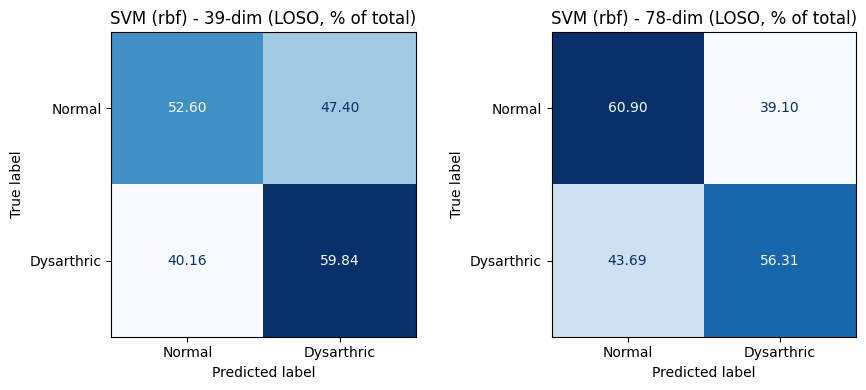

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, results, bk, label in [
    (axes[0], results_39, best_k_39, "39-dim"),
    (axes[1], results_78, best_k_78, "78-dim"),
]:
    all_true = results[bk]["all_true"]
    all_pred = results[bk]["all_pred"]
    cm = confusion_matrix(all_true, all_pred, normalize="true")
    disp = ConfusionMatrixDisplay(cm * 100, display_labels=["Normal", "Dysarthric"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues", values_format=".2f")
    ax.set_title(f"SVM ({bk}) - {label} (LOSO, % of total)")
plt.tight_layout()
plt.show()


## 6.6  Feature Importance (Linear SVM Weights)

RBF/poly kernels are black boxes -- no direct feature weights. For interpretability we train a dedicated **linear SVM** on both feature sets and inspect `|coef_|` (absolute weight of each feature in the decision boundary).

Features with higher absolute weight push the decision boundary more -- these are the acoustic dimensions that most separate normal from dysarthric speech.


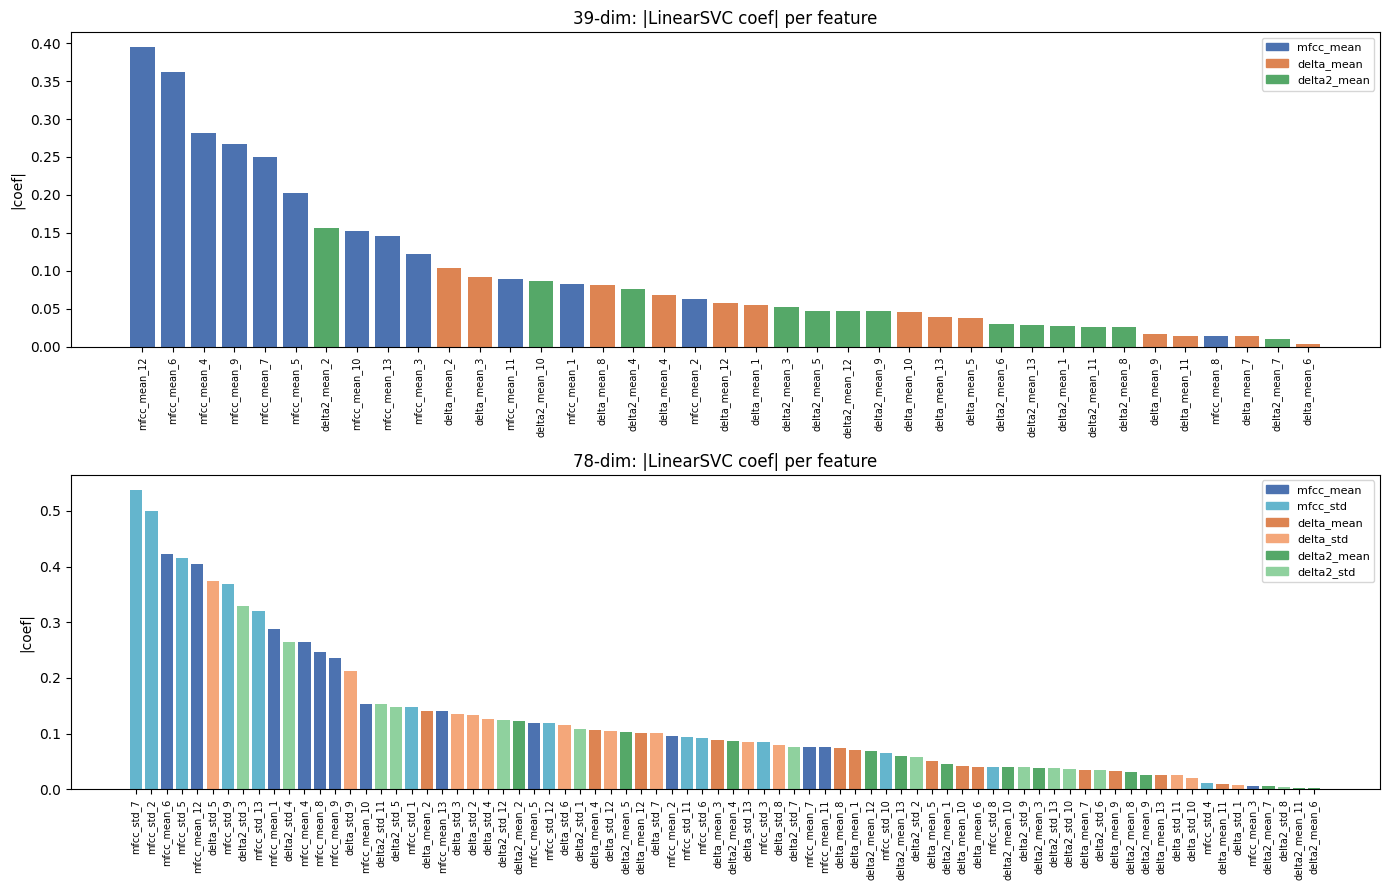


Top-10 features (39-dim):
   1. mfcc_mean_12          coef=0.3944
   2. mfcc_mean_6           coef=0.3619
   3. mfcc_mean_4           coef=0.2811
   4. mfcc_mean_9           coef=0.2677
   5. mfcc_mean_7           coef=0.2503
   6. mfcc_mean_5           coef=0.2023
   7. delta2_mean_2         coef=0.1569
   8. mfcc_mean_10          coef=0.1530
   9. mfcc_mean_13          coef=0.1455
  10. mfcc_mean_3           coef=0.1222

Top-10 features (78-dim):
   1. mfcc_std_7            coef=0.5376
   2. mfcc_std_2            coef=0.4998
   3. mfcc_mean_6           coef=0.4218
   4. mfcc_std_5            coef=0.4155
   5. mfcc_mean_12          coef=0.4038
   6. delta_std_5           coef=0.3736
   7. mfcc_std_9            coef=0.3692
   8. delta2_std_3          coef=0.3290
   9. mfcc_std_13           coef=0.3209
  10. mfcc_mean_1           coef=0.2877


In [7]:
def get_importances(X, y, names):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svm",    LinearSVC(max_iter=5000, random_state=42)),
    ])
    pipe.fit(X, y)
    coefs = np.abs(pipe.named_steps["svm"].coef_[0])
    return coefs

GROUP_COLOURS = {
    "mfcc_mean":   "#4C72B0",
    "mfcc_std":    "#64B5CD",
    "delta_mean":  "#DD8452",
    "delta_std":   "#F4A77A",
    "delta2_mean": "#55A868",
    "delta2_std":  "#8FD19E",
}

def name_to_colour(name):
    for prefix, colour in GROUP_COLOURS.items():
        if name.startswith(prefix):
            return colour
    return "grey"

coefs_39 = get_importances(X39, y_all, col_names_39)
coefs_78 = get_importances(X78, y_all, col_names_78)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

for ax, names, coefs, title in [
    (axes[0], col_names_39, coefs_39, "39-dim: |LinearSVC coef| per feature"),
    (axes[1], col_names_78, coefs_78, "78-dim: |LinearSVC coef| per feature"),
]:
    idx            = np.argsort(coefs)[::-1]
    sorted_names   = [names[i]  for i in idx]
    sorted_coefs   = coefs[idx]
    sorted_colours = [name_to_colour(n) for n in sorted_names]
    ax.bar(range(len(sorted_coefs)), sorted_coefs, color=sorted_colours)
    ax.set_xticks(range(len(sorted_names)))
    ax.set_xticklabels(sorted_names, rotation=90, fontsize=7)
    ax.set_title(title)
    ax.set_ylabel("|coef|")
    from matplotlib.patches import Patch
    legend_handles = [Patch(color=c, label=g) for g, c in GROUP_COLOURS.items()
                      if any(n.startswith(g) for n in names)]
    ax.legend(handles=legend_handles, fontsize=8)

plt.tight_layout()
plt.show()

print("\nTop-10 features (39-dim):")
for rank, i in enumerate(np.argsort(coefs_39)[::-1][:10], 1):
    print(f"  {rank:2d}. {col_names_39[i]:<20s}  coef={coefs_39[i]:.4f}")
print("\nTop-10 features (78-dim):")
for rank, i in enumerate(np.argsort(coefs_78)[::-1][:10], 1):
    print(f"  {rank:2d}. {col_names_78[i]:<20s}  coef={coefs_78[i]:.4f}")
